In [1]:
## data analysis and wrangling
import pandas as pd
import numpy as np
import random as rnd

## visualization
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# machine learning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import Perceptron
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier


#获取数据
train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')
combine = [train_data,test_data]

In [2]:
train_data.columns.values

array(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], dtype=object)

In [4]:
# 查看是否存在缺失值以及数据类型
train_data.info()
print("-"*40)
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Passenger

In [5]:
# 描述性统计
train_data.describe()
# Review survived rate using `percentiles=[.61, .62]` knowing our problem description mentions 38% survival rate.
# Review Parch distribution using `percentiles=[.75, .8]`
# SibSp distribution `[.68, .69]`
# Age and Fare `[.1, .2, .3, .4, .5, .6, .7, .8, .9, .99]`

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# 描述无序变量的特征
train_data.describe(include=['O'])

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [8]:
# 查看 Pclass与Survived 的相关性
train_data[['Pclass','Survived']].groupby(['Pclass'],as_index=False).mean().sort_values(by='Survived')

,Pclass,Survived
2,3,0.242363
1,2,0.472826
0,1,0.629630


In [9]:
train_data[['Sex','Survived']].groupby(['Sex'],as_index=False).mean().sort_values(by='Survived')
#女性获救概率高

,Sex,Survived
1,male,0.188908
0,female,0.742038


In [10]:
train_data[['Embarked','Survived']].groupby(['Embarked'],as_index=False).mean().sort_values(by='Survived')
#三个港口之间没什么区别

,Embarked,Survived
2,S,0.336957
1,Q,0.389610
0,C,0.553571


In [11]:
train_data[['SibSp','Survived']].groupby(['SibSp'],as_index=False).mean().sort_values(by='Survived',ascending=False)

,SibSp,Survived
1,1,0.535885
2,2,0.464286
0,0,0.345395
3,3,0.250000
4,4,0.166667
5,5,0.000000
6,8,0.000000


In [12]:
train_data[['Parch','Survived']].groupby(['Parch'],as_index=False).mean().sort_values(by='Survived',ascending=False)

,Parch,Survived
3,3,0.600000
1,1,0.550847
2,2,0.500000
0,0,0.343658
5,5,0.200000
4,4,0.000000
6,6,0.000000


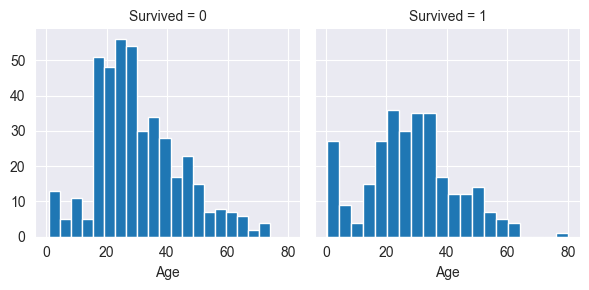

In [13]:
g = sns.FacetGrid(train_data,col='Survived')
g.map(plt.hist,'Age',bins=20)

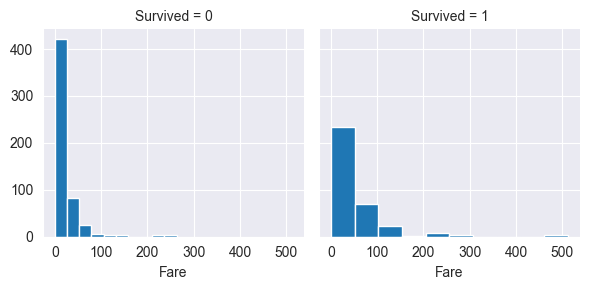

In [14]:
g = sns.FacetGrid(train_data,col='Survived')
g.map(plt.hist,'Fare',bins=10)
# 票价与生存率的关系,右偏,对模型训练不友好

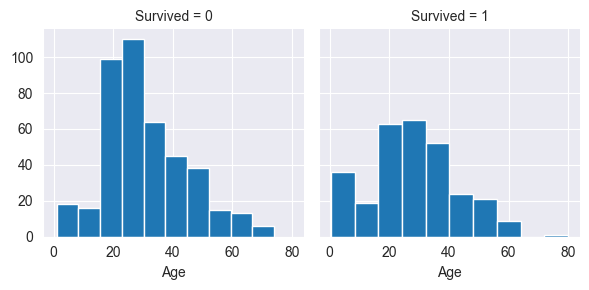

In [15]:
g = sns.FacetGrid(train_data,col='Survived')
g.map(plt.hist,'Age',bins=10)

(array([40., 14., 15., 31., 79., 98., 85., 84., 73., 45., 35., 35., 29.,
        16., 13., 11.,  4.,  5.,  1.,  1.]),
 array([ 0.42 ,  4.399,  8.378, 12.357, 16.336, 20.315, 24.294, 28.273,
        32.252, 36.231, 40.21 , 44.189, 48.168, 52.147, 56.126, 60.105,
        64.084, 68.063, 72.042, 76.021, 80.   ]),
 <BarContainer object of 20 artists>)

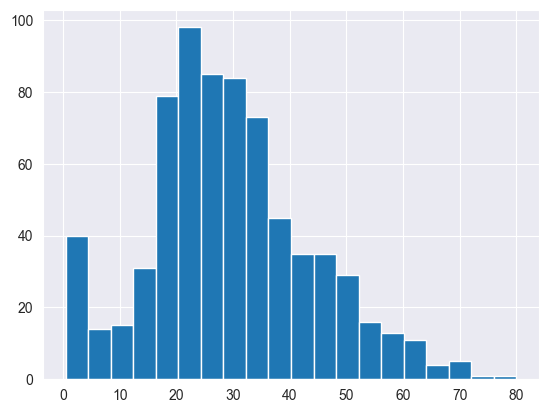

In [16]:
plt.hist(train_data['Age'][train_data.Age >= 0 ],bins='auto')

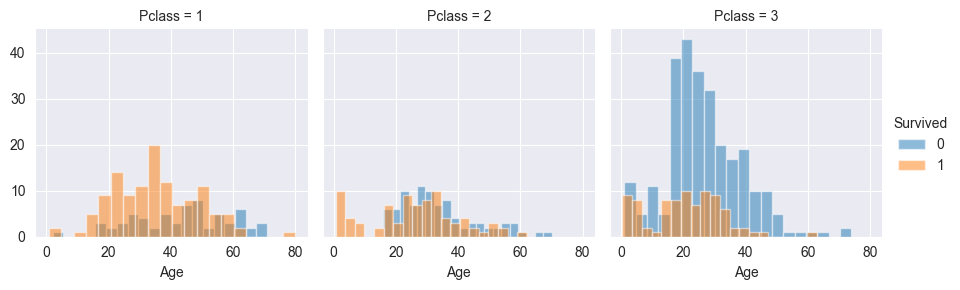

In [17]:
grid = sns.FacetGrid(train_data,hue="Survived",col='Pclass')
grid.map(plt.hist,'Age',alpha=.5,bins=20)
grid.add_legend()

D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the pointplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:723: UserWarning: Using the pointplot function without specifying `hue_order` is likely to produce an incorrect plot.
  warnings.warn(warning)
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1f77b4'` for the same effect.

  func(*plot_args, **plot_kwargs)
D:\newsoft\anaconda\envs\dl_pytorch\

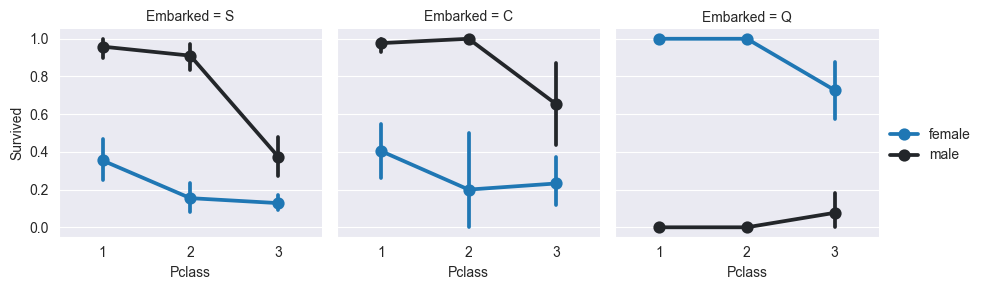

In [18]:
grid = sns.FacetGrid(train_data,col='Embarked')
grid.map(sns.pointplot,'Pclass','Survived','Sex')
grid.add_legend()

D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  func(*plot_args, **plot_kwargs)
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  func(*plot_args, **plot_kwargs)
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  func(*plot_args, **plot_kwargs)
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.


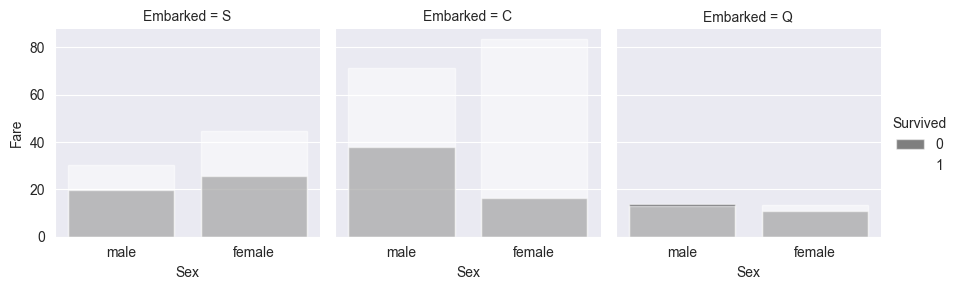

In [19]:
grid = sns.FacetGrid(train_data,col = 'Embarked',hue='Survived', palette={0: 'k', 1: 'w'})
grid.map(sns.barplot,'Sex','Fare',ci=None,alpha=.5)
grid.add_legend()

In [20]:
print('Before',train_data.shape,test_data.shape)

train_data = train_data.drop(['Cabin','Ticket'],axis =1)
test_data = test_data.drop(['Cabin','Ticket'],axis =1)

print('After',train_data.shape,test_data.shape)

Before (891, 12) (418, 11)
After (891, 10) (418, 9)


In [21]:
# str.extract 函数 用来处理字符型数据，可以用正则表达式从字符中抽取符合条件的数据 expend :布尔型，是否返回dataframe
# crosstab 函数 返回一个交叉表，交叉表是统计分组频率的特殊透视表 前面是列后面是行
combine = [train_data,test_data]
for dataset in combine:
    dataset['Title'] =dataset.Name.str.extract('([A-Za-z]+)\.',expand =False)
pd.crosstab(train_data['Title'],train_data['Sex'])

Sex,female,male
Title,,
Capt,0,1
Col,0,2
Countess,1,0
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40


In [22]:
for dataset in combine:
    dataset['Title'] = dataset['Title'].replace(['Lady','Countess','Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer','Dona'],'Rare')
    dataset['Title'] = dataset['Title'].replace(['Mlle','Ms'],'Miss')
    dataset['Title'] = dataset['Title'].replace('Mme','Mrs')

train_data[['Title','Survived']].groupby(['Title'],as_index=False).mean()

,Title,Survived
0,Master,0.575000
1,Miss,0.702703
2,Mr,0.156673
3,Mrs,0.793651
4,Rare,0.347826


In [23]:
title_mapping ={"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
for dataset in combine:
    dataset['Title'] = dataset['Title'].map(title_mapping) #转变数据格式
    dataset['Title'] = dataset['Title'].fillna(0) #把没有title的定为0
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,3
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,3
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,1


In [24]:
train_data = train_data.drop(['Name','PassengerId'],axis = 1)
test_data = test_data.drop(['Name'],axis = 1)
combine = [train_data,test_data]
train_data.shape , test_data.shape

((891, 9), (418, 9))

In [25]:
for dataset in combine:
    dataset['Sex'] = dataset['Sex'].map({'female':1,'male':0})
train_data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,0,3,0,22.0,1,0,7.2500,S,1
1,1,1,1,38.0,1,0,71.2833,C,3
2,1,3,1,26.0,0,0,7.9250,S,2
3,1,1,1,35.0,1,0,53.1000,S,3
4,0,3,0,35.0,0,0,8.0500,S,1


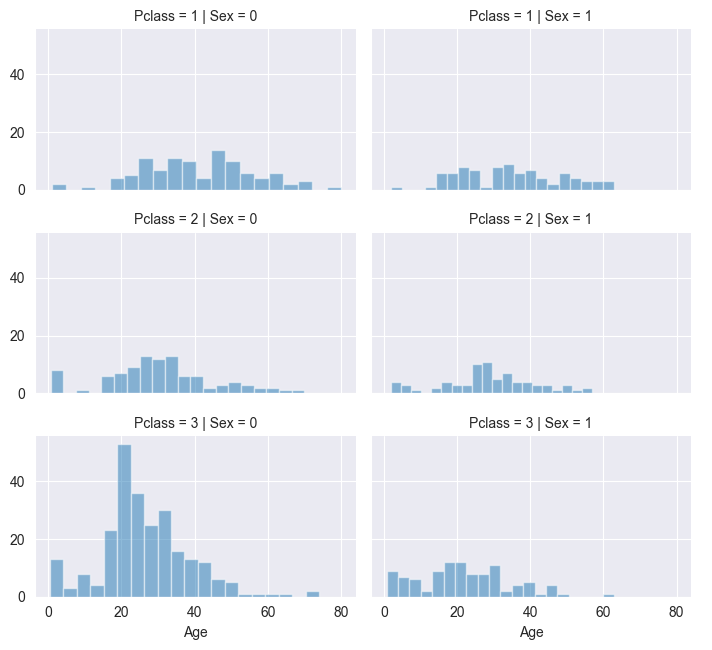

In [26]:
# 观察Pclass Gender 和 Age 的关系
grid = sns.FacetGrid(train_data,row ='Pclass',col = 'Sex',height=2.2,aspect=1.6)
grid.map(plt.hist,'Age',alpha=.5,bins=20)
grid.add_legend()

In [27]:
guess_ages = np.zeros((2,3))
guess_ages

array([[0., 0., 0.],
       [0., 0., 0.]])

In [28]:
for dataset in combine:
    for i in range(0,2):
        for j in range(1,4):
            guess_df = dataset[( dataset.Sex == i ) & ( dataset.Pclass ==j )].Age.dropna()
            age_guess = guess_df.median()
            # age_mean = guess_df.mean()
            # age_std = guess_df.std()
            # age_guess = rnd.uniform(age_mean - age_std, age_mean +age_std)

            guess_ages[i,j-1] = age_guess

            # 将随机的age小数转化到最近的.5
            # guess_ages[i,j-1] = int(age_guess/0.5 +0.5)*0.5
    for i in range(0,2):
        for j in range(1,4):
            dataset.loc[(dataset.Age.isnull())&(dataset.Sex==i)&(dataset.Pclass ==j),'Age'] = guess_ages[i,j-1]
    dataset.Age = dataset.Age.astype('int')
train_data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,0,3,0,22,1,0,7.2500,S,1
1,1,1,1,38,1,0,71.2833,C,3
2,1,3,1,26,0,0,7.9250,S,2
3,1,1,1,35,1,0,53.1000,S,3
4,0,3,0,35,0,0,8.0500,S,1


In [31]:
train_data['Ageband'] = pd.cut(train_data['Age'],5)

train_data[['Ageband','Survived']].groupby(['Ageband'],as_index = False).mean().sort_values(by='Ageband',ascending = True)

,Ageband,Survived
0,"(-0.004, 0.8]",0.550000
1,"(0.8, 1.6]",0.337374
2,"(1.6, 2.4]",0.412037
3,"(2.4, 3.2]",0.434783
4,"(3.2, 4.0]",0.090909


In [32]:
for dataset in combine:
    dataset.loc[dataset.Age <=16,'Age'] = 0
    dataset.loc[(dataset.Age >16) & (dataset.Age <= 32),'Age'] = 1
    dataset.loc[(dataset.Age >32) & (dataset.Age <= 48),'Age'] = 2
    dataset.loc[(dataset.Age >48) & (dataset.Age <= 64),'Age'] = 3
    dataset.loc[dataset.Age >64,'Age'] = 4

train_data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,Ageband
0,0,3,0,0,1,0,7.2500,S,1,"(0.8, 1.6]"
1,1,1,1,0,1,0,71.2833,C,3,"(1.6, 2.4]"
2,1,3,1,0,0,0,7.9250,S,2,"(0.8, 1.6]"
3,1,1,1,0,1,0,53.1000,S,3,"(1.6, 2.4]"
4,0,3,0,0,0,0,8.0500,S,1,"(1.6, 2.4]"


In [33]:
train_data = train_data.drop(['Ageband'],axis = 1)
combine = [train_data,test_data]
train_data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,0,3,0,0,1,0,7.2500,S,1
1,1,1,1,0,1,0,71.2833,C,3
2,1,3,1,0,0,0,7.9250,S,2
3,1,1,1,0,1,0,53.1000,S,3
4,0,3,0,0,0,0,8.0500,S,1


In [34]:
for dataset in combine:
    dataset['FamilySize'] = dataset['Parch']+dataset['SibSp']+1

train_data[['FamilySize','Survived']].groupby(['FamilySize'],as_index = False).mean().sort_values(by = 'Survived',ascending = False)

,FamilySize,Survived
3,4,0.724138
2,3,0.578431
1,2,0.552795
6,7,0.333333
0,1,0.303538
4,5,0.200000
5,6,0.136364
7,8,0.000000
8,11,0.000000


In [35]:
for dataset in combine:
    dataset['IsAlone'] = 0
    dataset.loc[dataset.FamilySize == 1,'IsAlone'] =1

train_data[['IsAlone','Survived']].groupby(['IsAlone'],as_index=False).mean()

,IsAlone,Survived
0,0,0.505650
1,1,0.303538


In [36]:
train_data = train_data.drop(['Parch','SibSp','FamilySize'],axis = 1)
test_data = test_data.drop(['Parch','SibSp','FamilySize'],axis = 1)
combine =[train_data,test_data]

train_data.head()

,Survived,Pclass,Sex,Age,Fare,Embarked,Title,IsAlone
0,0,3,0,0,7.2500,S,1,0
1,1,1,1,0,71.2833,C,3,0
2,1,3,1,0,7.9250,S,2,1
3,1,1,1,0,53.1000,S,3,0
4,0,3,0,0,8.0500,S,1,1


In [37]:
for dataset in combine:
    dataset['Age*Pclass'] = dataset.Age * dataset.Pclass

train_data[['Age*Pclass','Age','Pclass']].head(10)

,Age*Pclass,Age,Pclass
0,0,0,3
1,0,0,1
2,0,0,3
3,0,0,1
4,0,0,3
5,0,0,3
6,0,0,1
7,0,0,3
8,0,0,3
9,0,0,2


In [38]:
# mode function 返回众数
freq_port = train_data.Embarked.dropna().mode()[0]
freq_port
'S'


for dataset in combine:
    dataset['Embarked'] = dataset['Embarked'].fillna(freq_port)

train_data[['Embarked','Survived']].groupby(['Embarked'],as_index =False).mean()


,Embarked,Survived
0,C,0.553571
1,Q,0.389610
2,S,0.339009


In [39]:
for dataset in combine:
    dataset['Embarked'] =dataset['Embarked'].map({'S':0,'C':1,'Q':2}).astype(int)

train_data.head()

,Survived,Pclass,Sex,Age,Fare,Embarked,Title,IsAlone,Age*Pclass
0,0,3,0,0,7.2500,0,1,0,0
1,1,1,1,0,71.2833,1,3,0,0
2,1,3,1,0,7.9250,0,2,1,0
3,1,1,1,0,53.1000,0,3,0,0
4,0,3,0,0,8.0500,0,1,1,0


In [40]:
test_data['Fare']=test_data['Fare'].fillna(test_data['Fare'].dropna().median())
test_data.head()
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Sex          418 non-null    int64  
 3   Age          418 non-null    int32  
 4   Fare         418 non-null    float64
 5   Embarked     418 non-null    int32  
 6   Title        418 non-null    int64  
 7   IsAlone      418 non-null    int64  
 8   Age*Pclass   418 non-null    int64  
dtypes: float64(1), int32(2), int64(6)
memory usage: 26.2 KB


In [41]:
# qcut 根据值的频率确定区间
train_data['Fareband'] = pd.qcut(train_data['Fare'],4)
train_data[['Fareband','Survived']].groupby(['Fareband'],as_index =False).mean().sort_values('Fareband',ascending=True)

,Fareband,Survived
0,"(-0.001, 7.91]",0.197309
1,"(7.91, 14.454]",0.303571
2,"(14.454, 31.0]",0.454955
3,"(31.0, 512.329]",0.581081


In [42]:
for dataset in combine:
    dataset.loc[dataset.Fare <= 7.91,'Fare'] = 0
    dataset.loc[(dataset.Fare>7.91)&(dataset.Fare <=14.454),'Fare'] = 1
    dataset.loc[(dataset.Fare>14.454)&(dataset.Fare <=31),'Fare'] = 2
    dataset.loc[dataset.Fare>31,'Fare'] = 3
    dataset.Fare = dataset.Fare.astype(int)

train_data = train_data.drop(['Fareband'],axis =1 )
combine = [train_data,test_data]

train_data.head()

,Survived,Pclass,Sex,Age,Fare,Embarked,Title,IsAlone,Age*Pclass
0,0,3,0,0,0,0,1,0,0
1,1,1,1,0,3,1,3,0,0
2,1,3,1,0,1,0,2,1,0
3,1,1,1,0,3,0,3,0,0
4,0,3,0,0,1,0,1,1,0


In [43]:
test_data.head()

,PassengerId,Pclass,Sex,Age,Fare,Embarked,Title,IsAlone,Age*Pclass
0,892,3,0,0,0,2,1,1,0
1,893,3,1,0,0,0,3,0,0
2,894,2,0,0,1,2,1,1,0
3,895,3,0,0,1,0,1,1,0
4,896,3,1,0,1,0,3,0,0


In [44]:
X_train = train_data.drop('Survived',axis = 1)
Y_train = train_data.Survived
X_test = test_data.drop('PassengerId',axis =1)
X_train.shape, Y_train.shape,X_test.shape

((891, 8), (891,), (418, 8))

In [45]:
# Logistic Regression
logreg = LogisticRegression()
logreg.fit(X_train,Y_train)
Y_pred = logreg.predict(X_test)
acc_log = round(logreg.score(X_train,Y_train)*100,2)
acc_log

77.89

In [46]:
coeff_df = pd.DataFrame(train_data.columns.delete(0))
coeff_df.columns = ['Feature']
coeff_df['Correlation'] = pd.Series(logreg.coef_[0])

coeff_df.sort_values(by = 'Correlation',ascending = False)

,Feature,Correlation
1,Sex,2.177110
5,Title,0.408368
4,Embarked,0.301519
6,IsAlone,0.028601
2,Age,0.000000
7,Age*Pclass,0.000000
3,Fare,-0.042672
0,Pclass,-0.963742


In [47]:
# Support Vector Machines
svc = SVC()
svc.fit(X_train,Y_train)
Y_pred = svc.predict(X_test)
acc_svc = round(svc.score(X_train,Y_train)*100,2)
acc_svc

82.83

In [48]:
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train,Y_train)
Y_pred = knn.predict(X_test)
acc_knn = round(knn.score(X_train,Y_train)*100,2)
acc_knn

79.46

In [49]:
# Gaussian Naive Bayes
gaussian = GaussianNB()
gaussian.fit(X_train,Y_train)
Y_pred = gaussian.predict(X_test)
acc_gaussian =round(gaussian.score(X_train,Y_train)*100,2)
acc_gaussian

76.99

In [50]:
# Percept
perceptron = Perceptron()
perceptron.fit(X_train, Y_train)
Y_pred = perceptron.predict(X_test)
acc_perceptron = round(perceptron.score(X_train, Y_train) * 100, 2)
acc_perceptron

78.9

In [51]:
# Linear SVC
linear_svc = LinearSVC()
linear_svc.fit(X_train, Y_train)
Y_pred = linear_svc.predict(X_test)
acc_linear_svc = round(linear_svc.score(X_train, Y_train) * 100, 2)
acc_linear_svc

D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
D:\newsoft\anaconda\envs\dl_pytorch\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


78.11

In [52]:
# Stochastic Gradient Descent
sgd = SGDClassifier()
sgd.fit(X_train, Y_train)
Y_pred = sgd.predict(X_test)
acc_sgd = round(sgd.score(X_train, Y_train) * 100, 2)
acc_sgd

79.12

In [53]:
# Decision Tree
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train, Y_train)
Y_pred = decision_tree.predict(X_test)
acc_decision_tree = round(decision_tree.score(X_train, Y_train) * 100, 2)
acc_decision_tree

84.29

In [54]:
#Random Forest
random_forest = RandomForestClassifier(n_estimators=100)
random_forest.fit(X_train, Y_train)
Y_pred = random_forest.predict(X_test)
random_forest.score(X_train, Y_train)
acc_random_forest = round(random_forest.score(X_train, Y_train) * 100, 2)
acc_random_forest

84.29

In [55]:
models = pd.DataFrame({
    'Model': ['Support Vector Machines', 'KNN', 'Logistic Regression', 
              'Random Forest', 'Naive Bayes', 'Perceptron', 
              'Stochastic Gradient Decent', 'Linear SVC', 
              'Decision Tree'],
    'Score': [acc_svc, acc_knn, acc_log, 
              acc_random_forest, acc_gaussian, acc_perceptron, 
              acc_sgd, acc_linear_svc, acc_decision_tree]})
models.sort_values(by='Score', ascending=False)

,Model,Score
3,Random Forest,84.29
8,Decision Tree,84.29
0,Support Vector Machines,82.83
1,KNN,79.46
6,Stochastic Gradient Decent,79.12
5,Perceptron,78.90
7,Linear SVC,78.11
2,Logistic Regression,77.89
4,Naive Bayes,76.99


In [56]:
#提交数据
submission = pd.DataFrame({
        "PassengerId": test_data["PassengerId"],
        "Survived": Y_pred
    })
submission.to_csv('submission.csv', index=False)